# L3.2 · Find groups in customer activity

**Day 3 slides** 11–13 and 19

### The problem

Some customers use the app often and some visit a branch more. Can a computer find groups without knowing group names in advance?

### What we’re doing

Compare possible group counts, describe the groups in the original units, and check how much a different grouping agrees.

### Why we’re doing it

A group becomes useful when we can explain the behaviour its members share. A picture and a small summary table help us check that.

Read the text above a code cell, then click the cell and press
**Shift + Enter**. Run from the top. The files contain synthetic course data.

## Setup · Open the data

Use 600 customer rows. See the original units for logins, visits, spend and time since the last transaction. Each row describes one person. Run this cell as written. The import lines make the tools
available. The folder lines find the supplied data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from pathlib import Path

here = Path.cwd()
data = next((folder / "data" for folder in (here, *here.parents)
             if (folder / "data" / "loan_applications.csv").is_file()), None)
if data is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

inputs = ["digital_logins_30d", "branch_visits_90d", "card_spend_monthly_aed", "days_since_last_txn"]
customers = pd.read_csv(data / "customers_raw.csv", usecols=["customer_id"] + inputs)
customers = customers.drop_duplicates("customer_id").dropna()
customers = customers[(customers[inputs] >= 0).all(axis=1)]

sample = customers.sample(600, random_state=42).copy()
display(sample[inputs].head(4))

,digital_logins_30d,branch_visits_90d,card_spend_monthly_aed,days_since_last_txn
1797,22.0,0,9410.39,0
222949,22.0,0,0.00,6
140272,15.0,1,0.00,2
109548,26.0,0,2087.80,5


## 1 · Put the clues on comparable scales

**What we’re doing.** Compress the very large spending numbers with a log, then put all four clues on similar scales.

**Why.** Grouping is based on distance. Amounts in AED are much larger than counts, so changing scales helps each clue have a say.

**Look for.** The average for each scaled column is near zero. We will describe groups in the original units afterwards.

In [2]:
behaviour = sample[inputs].copy()
behaviour["card_spend_monthly_aed"] = np.log1p(behaviour["card_spend_monthly_aed"])
features = StandardScaler().fit_transform(behaviour)
display(pd.Series(features.mean(axis=0), index=inputs, name="Mean after scaling").round(3))

digital_logins_30d       -0.0
branch_visits_90d        -0.0
card_spend_monthly_aed    0.0
days_since_last_txn      -0.0
Name: Mean after scaling, dtype: float64

## 2 · Compare possible group counts

**What we’re doing.** Make three different groupings and record inertia and silhouette.

**Why.** Adding centres usually improves inertia, so we also check how separate the groups look. Silhouette gets larger when rows fit their own group better than nearby groups.

**Look for.** We use the count with highest silhouette for this walkthrough. In practice, check stability and whether people can explain and use the groups.

In [3]:
fitted = {}
rows = []
for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(features)
    fitted[k] = model
    rows.append([k, model.inertia_, silhouette_score(features, model.labels_)])
comparison = pd.DataFrame(rows, columns=["Groups", "Inertia", "Silhouette"])
display(comparison.round(3))
chosen_k = int(comparison.sort_values("Silhouette", ascending=False).iloc[0]["Groups"])

,Groups,Inertia,Silhouette
0,2,1819.592,0.286
1,3,1495.140,0.283
2,4,1214.274,0.297


## 3 · Read a profile in familiar units

**What we’re doing.** Show the middle values in each group and count its customers. Describe one group using its observed activity.

**Why.** A group number has no meaning by itself. A description such as most digital logins in this sample tells us what the rows share.

**Look for.** Compare each group’s counts and numbers before giving it a name. Names describe this sample.

In [4]:
labels = fitted[chosen_k].labels_
sample["segment"] = labels + 1
profiles = sample.groupby("segment")[inputs].median()
profiles.insert(0, "Customers", sample["segment"].value_counts())
display(profiles.round(1))
digital = profiles["digital_logins_30d"].idxmax()
print("Group with the highest median digital logins:", digital)

,Customers,digital_logins_30d,branch_visits_90d,card_spend_monthly_aed,days_since_last_txn
segment,,,,,
1,185,20.0,0.0,0.0,4.0
2,73,19.0,0.0,2229.5,17.0
3,233,22.0,0.0,3413.6,3.0
4,109,16.0,2.0,2475.9,3.0


Group with the highest median digital logins: 3


## 4 · Compare with another grouping

**What we’re doing.** Try a different random start and a bottom-up method. Compare which pairs of rows ended up together.

**Why.** A useful grouping should be stable enough to explain. A different start or approach can reveal whether small changes produce very different groups.

**Look for.** The agreement score equals one for matching groups even when their numbers are reversed. Around zero means roughly chance agreement.

In [5]:
new_start = KMeans(n_clusters=chosen_k, n_init=10, random_state=7).fit_predict(features)
merged_groups = AgglomerativeClustering(n_clusters=chosen_k).fit_predict(features)
print("Agreement · another start:", round(adjusted_rand_score(labels, new_start), 3))
print("Agreement · bottom-up merges:", round(adjusted_rand_score(labels, merged_groups), 3))

Agreement · another start: 1.0
Agreement · bottom-up merges: 0.622


## 5 · See the groups in two dimensions

**What we’re doing.** Draw a map using two combined directions from the four clues. Colour each point by its assigned group.

**Why.** PCA makes it possible to draw four inputs on one two-dimensional page. It keeps much of the variation but can hide some separation from the full data.

**Look for.** Each point is a customer. The axes are new combinations of the inputs. The table from step 3 is easier to use when explaining what a group does.

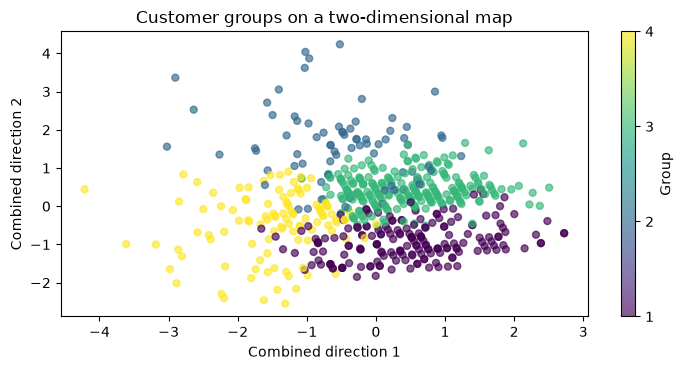

In [6]:
view = PCA(n_components=2).fit_transform(features)
fig, ax = plt.subplots(figsize=(7.4, 3.8))
scatter = ax.scatter(view[:, 0], view[:, 1], c=sample["segment"], cmap="viridis", s=25, alpha=.65)
ax.set(title="Customer groups on a two-dimensional map", xlabel="Combined direction 1", ylabel="Combined direction 2")
fig.colorbar(scatter, ax=ax, ticks=range(1, chosen_k + 1), label="Group")
plt.tight_layout()
plt.show()

## 6 · Check the table we would hand off

**What we’re doing.** Show the customer ID and the assigned group together.

**Why.** Another exercise can join a group onto a customer table using the ID. Giving each customer one row keeps that join clear.

**Look for.** The preview shows a unique ID and one group per customer. This small table illustrates the form of the full-course lab output.

In [7]:
assignments = sample[["customer_id", "segment"]]
display(assignments.head())
print("One row per customer:", assignments["customer_id"].is_unique)

,customer_id,segment
1797,HGB1214000,3
222949,HGB1144636,1
140272,HGB1045505,1
109548,HGB1137888,3
55499,HGB1184965,2


One row per customer: True


### Your turn

Choose a group from step 3. Describe it using two numbers and the number of customers behind them.